# Analysis: GP-BO vs CMA-ES

Reads the saved runs in `results/<method>/` and compares methods across effective dimension and orientation.
This notebook does not run any optimiser.

**Hypotheses**
- **H1 (rotation):** ARD-BO has a larger rotation penalty than CMA-ES. ARD assigns a separate length scale to each input coordinate, whereas CMA-ES can adapt the orientation of its search distribution through a full covariance matrix (Rasmussen & Williams, 2006; Hansen, 2016).
- **H2 (effective dimension):** ARD-BO's rotation penalty tends to be greater at smaller effective dimensions. In the aligned case, more coordinates are irrelevant, giving ARD greater scope to down-weight them through large length scales (Rasmussen & Williams, 2006).
- **H3 (kernel comparison):** ARD-BO has a larger rotation penalty than isotropic BO. Rotation is expected to reduce ARD's benefit from learning separate length scales for individual coordinates.

**Rotation penalty** = log10(rotated final value / aligned final value), for the same method, d, problem seed and method seed.
Above 0 means rotation made the method worse; 1 means ten times worse.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
RESULTS_DIR = Path("../results")

# Shared experimental settings (match code/cmaes.py and code/shared_bo.py).
D = 20
EFFECTIVE_DIMS = [2, 5, 10, 15, 20]
PROBLEM_SEEDS = [0, 1, 2, 3, 4]
METHOD_SEEDS = [100, 101]
BUDGET = 400

# Methods to compare: results folder name -> plot label.
METHODS = {
    "bo_ard": "GP-BO (ARD)",
    "isotropic_bo": "GP-BO (isotropic)",
    "cmaes": "CMA-ES",
    "random_search": "Random search",
}

## 2. Load results

Each CSV is one run with one row per evaluation. The filename pattern skips files such as `test_run.csv`.

In [3]:
KEY_COLUMNS = ["method", "d", "problem_seed", "rotated", "method_seed"]


def load_results(results_dir=RESULTS_DIR, methods=METHODS):
    """Combine every saved run into one long table (one row per evaluation)."""
    frames = []
    for method in methods:
        for path in sorted((results_dir / method).glob("d*_problem*_method*.csv")):
            frames.append(pd.read_csv(path))

    if not frames:
        raise FileNotFoundError(f"No result files found in {results_dir}.")

    df = pd.concat(frames, ignore_index=True)
    df["orientation"] = np.where(df["rotated"], "rotated", "aligned")
    return df

In [4]:
df = load_results()

# Only methods with saved results are compared below.
available = [m for m in METHODS if m in set(df["method"])]
print("Methods analysed:", [METHODS[m] for m in available])

Methods analysed: ['GP-BO (ARD)', 'GP-BO (isotropic)', 'CMA-ES', 'Random search']


### 2.1 Checks

Each method should have 5 dims x 5 problems x 2 orientations x 2 method seeds = 100 runs, each with 400 evaluations.

In [5]:
evals_per_run = df.groupby(KEY_COLUMNS).size()
bad_runs = evals_per_run[evals_per_run != BUDGET]
print("Runs without exactly", BUDGET, "evaluations:", len(bad_runs))

expected = len(EFFECTIVE_DIMS) * len(PROBLEM_SEEDS) * 2 * len(METHOD_SEEDS)
runs_per_method = evals_per_run.groupby("method").size()
print(f"\nRuns per method (expected {expected}):")
print(runs_per_method.rename(index=METHODS).to_string())

Runs without exactly 400 evaluations: 0

Runs per method (expected 100):
method
GP-BO (ARD)          100
CMA-ES               100
GP-BO (isotropic)    100
Random search        100


## 3. Convergence curves

Best value found against evaluations: one panel per effective dimension, aligned vs rotated, one line per method.

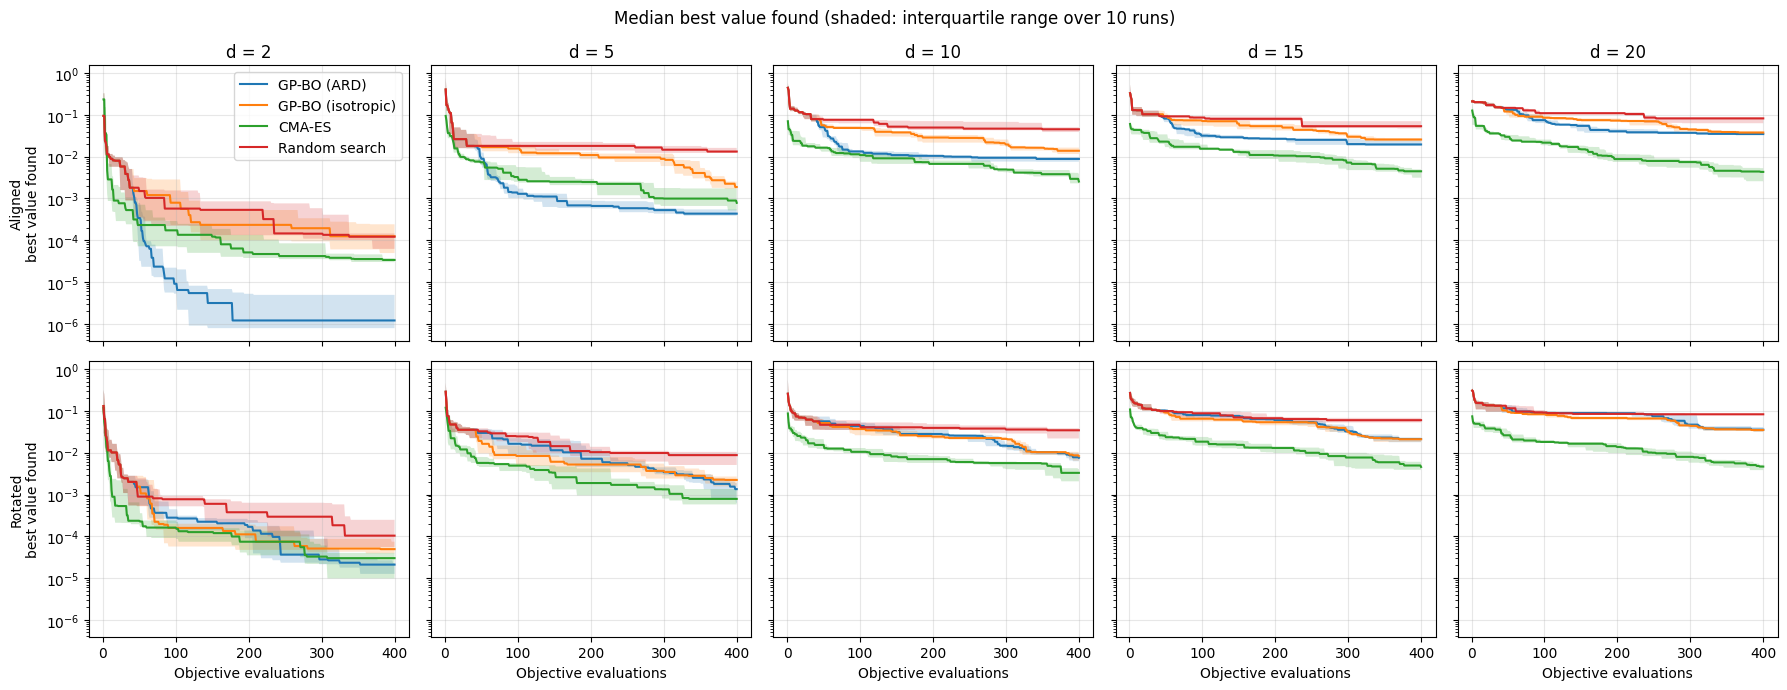

In [6]:
fig, axes = plt.subplots(
    2, len(EFFECTIVE_DIMS), figsize=(18, 7), sharex=True, sharey=True
)

for row, orientation in enumerate(["aligned", "rotated"]):
    for col, d in enumerate(EFFECTIVE_DIMS):
        ax = axes[row, col]
        subset = df[(df["d"] == d) & (df["orientation"] == orientation)]

        for method in available:
            curves = subset[subset["method"] == method].pivot_table(
                index="evaluation",
                columns=["problem_seed", "method_seed"],
                values="best_so_far",
            )
            q25, q50, q75 = (curves.quantile(q, axis=1) for q in (0.25, 0.5, 0.75))
            ax.plot(q50.index, q50, label=METHODS[method])
            ax.fill_between(q50.index, q25, q75, alpha=0.2)

        ax.set_yscale("log")
        ax.grid(True, alpha=0.3)
        if row == 0:
            ax.set_title(f"d = {d}")
        if row == 1:
            ax.set_xlabel("Objective evaluations")
        if col == 0:
            ax.set_ylabel(f"{orientation.capitalize()}\nbest value found")

axes[0, 0].legend()
fig.suptitle("Median best value found (shaded: interquartile range over 10 runs)")
plt.tight_layout()
plt.show()

## 4. Final performance

Summary of `best_so_far` at evaluation 400 (= simple regret, since the minimum is 0).

In [7]:
# One row per run: the best value after the full budget.
final = df[df["evaluation"] == BUDGET].copy()


def q25(x):
    return x.quantile(0.25)


def q75(x):
    return x.quantile(0.75)


summary = (
    final.groupby(["method", "d", "orientation"])["best_so_far"]
    .agg(median="median", q25=q25, q75=q75, mean="mean", runs="size")
    .reset_index()
)
summary["method"] = summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.3g}".format):
    display(summary)

,method,d,orientation,median,q25,q75,mean,runs
0,GP-BO (ARD),2,aligned,1.2e-06,7.86e-07,4.91e-06,4.53e-06,10
1,GP-BO (ARD),2,rotated,2.1e-05,1.26e-05,2.28e-05,2.27e-05,10
2,GP-BO (ARD),5,aligned,0.000433,0.000384,0.000546,0.000445,10
3,GP-BO (ARD),5,rotated,0.00134,0.000632,0.00188,0.00172,10
4,GP-BO (ARD),10,aligned,0.00883,0.00757,0.00964,0.00827,10
5,GP-BO (ARD),10,rotated,0.00755,0.00625,0.00871,0.00908,10
6,GP-BO (ARD),15,aligned,0.0196,0.0184,0.0243,0.0212,10
7,GP-BO (ARD),15,rotated,0.0213,0.0178,0.0233,0.0238,10
8,GP-BO (ARD),20,aligned,0.0348,0.0342,0.0375,0.0358,10
9,GP-BO (ARD),20,rotated,0.0356,0.0317,0.0412,0.0446,10


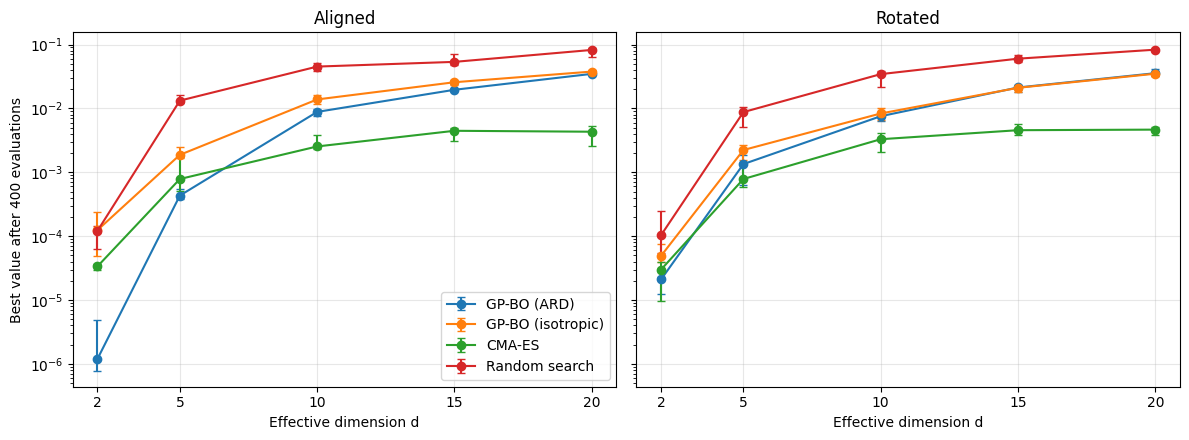

In [8]:
# Final best value against d, one line per method.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, orientation in zip(axes, ["aligned", "rotated"]):
    for method in available:
        values = final[(final["method"] == method) & (final["orientation"] == orientation)]
        stats = values.groupby("d")["best_so_far"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.errorbar(
            stats.index,
            stats[0.5],
            yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
            marker="o",
            capsize=3,
            label=METHODS[method],
        )

    ax.set_yscale("log")
    ax.set_xticks(EFFECTIVE_DIMS)
    ax.set_title(orientation.capitalize())
    ax.set_xlabel("Effective dimension d")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel(f"Best value after {BUDGET} evaluations")
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Rotation penalty

Each rotated run is matched with its aligned twin (same method, d, problem seed and method seed).
Above 0: rotation made the method worse.

In [9]:
# Match each rotated run with its aligned twin (same method, d and seeds).
pairs = final.pivot_table(
    index=["method", "d", "problem_seed", "method_seed"],
    columns="rotated",
    values="best_so_far",
).rename(columns={False: "aligned", True: "rotated"})

# > 0: rotation made the method worse; 1 = ten times worse.
pairs["log10_rotation_effect"] = np.log10(pairs["rotated"] / pairs["aligned"])
pairs = pairs.reset_index()

rotation_summary = (
    pairs.groupby(["method", "d"])["log10_rotation_effect"]
    .agg(median="median", q25=q25, q75=q75)
    .join(
        pairs.groupby(["method", "d"])["log10_rotation_effect"]
        .apply(lambda x: (x > 0).mean())
        .rename("fraction_worse_when_rotated")
    )
    .reset_index()
)
rotation_summary["method"] = rotation_summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.2f}".format):
    display(rotation_summary)

,method,d,median,q25,q75,fraction_worse_when_rotated
0,GP-BO (ARD),2,1.25,0.42,1.41,0.90
1,GP-BO (ARD),5,0.39,0.11,0.65,1.00
2,GP-BO (ARD),10,0.04,-0.14,0.11,0.60
3,GP-BO (ARD),15,-0.06,-0.09,0.12,0.40
4,GP-BO (ARD),20,-0.02,-0.04,0.08,0.40
5,CMA-ES,2,-0.24,-0.38,0.11,0.30
6,CMA-ES,5,-0.07,-0.21,0.33,0.40
7,CMA-ES,10,0.04,-0.29,0.25,0.50
8,CMA-ES,15,-0.02,-0.03,0.06,0.30
9,CMA-ES,20,0.04,-0.20,0.22,0.60


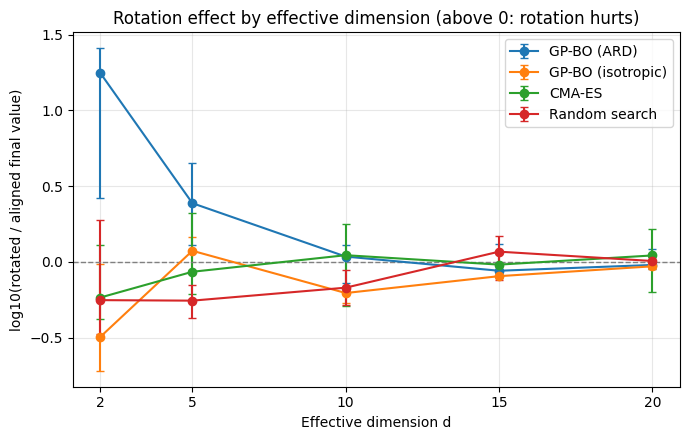

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for method in available:
    values = pairs[pairs["method"] == method]
    stats = values.groupby("d")["log10_rotation_effect"].quantile([0.25, 0.5, 0.75]).unstack()
    ax.errorbar(
        stats.index,
        stats[0.5],
        yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
        marker="o",
        capsize=3,
        label=METHODS[method],
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("log10(rotated / aligned final value)")
ax.set_title("Rotation effect by effective dimension (above 0: rotation hurts)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. H1: ARD-BO vs CMA-ES rotation penalty

Both methods solve the same problems, but a method seed means different things in BO and CMA-ES.
So each method's penalty is first averaged over its two method seeds, giving one penalty per problem (5 pairs per d).
H1 predicts **ARD penalty − CMA-ES penalty > 0**.

,bo_ard_penalty,cmaes_penalty,median_difference,fraction_first_larger,pairs
d,,,,,
2,0.81,-0.24,1.02,1.00,5
5,0.60,0.05,0.19,0.80,5
10,0.03,0.00,0.10,0.60,5
15,-0.02,-0.02,-0.04,0.40,5
20,0.06,0.17,0.01,0.80,5


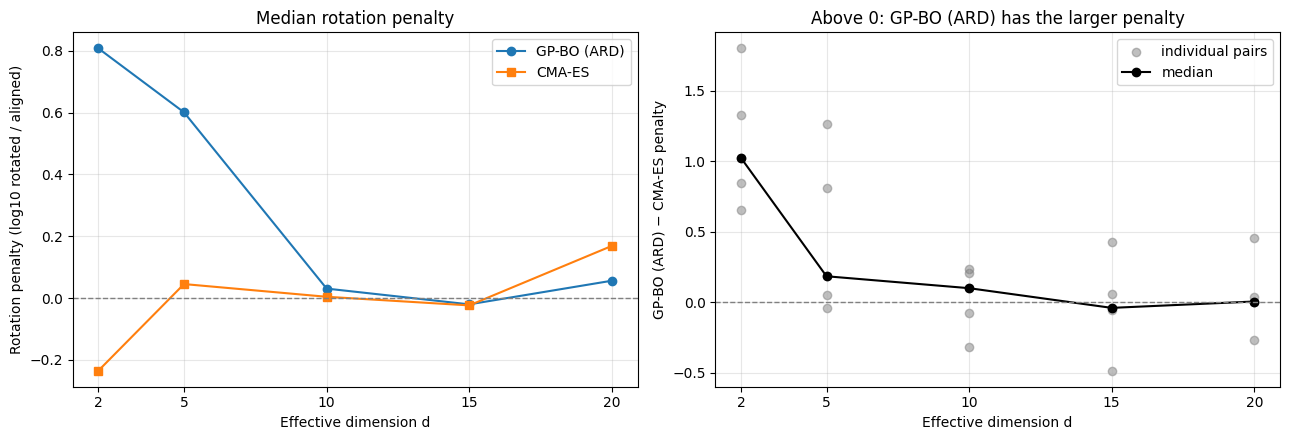

In [11]:
def plot_penalty_comparison(paired, first, second):
    """Left: each method's median rotation penalty. Right: paired differences."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    for method, marker in [(first, "o"), (second, "s")]:
        median = paired.groupby("d")[method].median()
        ax1.plot(median.index, median, marker=marker, label=METHODS[method])

    ax1.set_ylabel("Rotation penalty (log10 rotated / aligned)")
    ax1.set_title("Median rotation penalty")
    ax1.legend()

    difference = paired[first] - paired[second]
    ax2.scatter(
        difference.index.get_level_values("d"), difference,
        color="grey", alpha=0.5, label="individual pairs",
    )
    median_difference = difference.groupby(level="d").median()
    ax2.plot(median_difference.index, median_difference, marker="o", color="black", label="median")
    ax2.set_ylabel(f"{METHODS[first]} − {METHODS[second]} penalty")
    ax2.set_title(f"Above 0: {METHODS[first]} has the larger penalty")
    ax2.legend()

    for ax in (ax1, ax2):
        ax.axhline(0, color="grey", linestyle="--", linewidth=1)
        ax.set_xticks(EFFECTIVE_DIMS)
        ax.set_xlabel("Effective dimension d")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def summarise_penalty_difference(paired, first, second):
    """Median penalties and paired difference by d."""
    difference = paired[first] - paired[second]
    return pd.DataFrame({
        f"{first}_penalty": paired.groupby("d")[first].median(),
        f"{second}_penalty": paired.groupby("d")[second].median(),
        "median_difference": difference.groupby(level="d").median(),
        "fraction_first_larger": (difference > 0).groupby(level="d").mean(),
        "pairs": difference.groupby(level="d").size(),
    })


# One penalty per method and problem (averaged over method seeds).
problem_penalty = (
    pairs.groupby(["method", "d", "problem_seed"])["log10_rotation_effect"]
    .mean()
    .unstack("method")
)
h1 = problem_penalty[["bo_ard", "cmaes"]]

with pd.option_context("display.float_format", "{:.2f}".format):
    display(summarise_penalty_difference(h1, "bo_ard", "cmaes"))

plot_penalty_comparison(h1, "bo_ard", "cmaes")

## 7. H2: ARD-BO rotation penalty vs effective dimension

H2 predicts ARD's rotation penalty is larger at small d, where more coordinates are irrelevant in the aligned case.

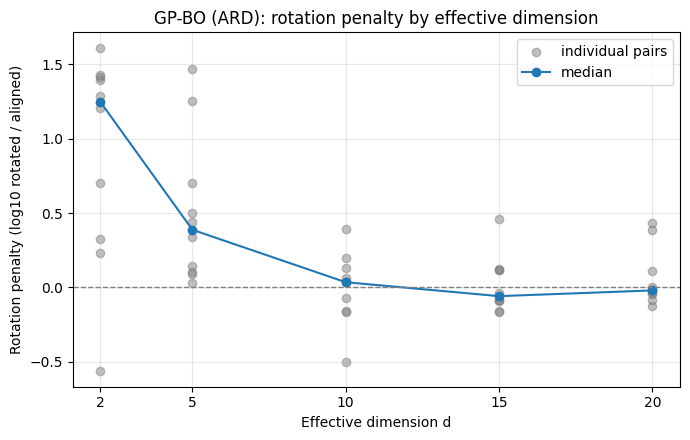

In [12]:
ard_pairs = pairs[pairs["method"] == "bo_ard"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(
    ard_pairs["d"], ard_pairs["log10_rotation_effect"],
    color="grey", alpha=0.5, label="individual pairs",
)
median = ard_pairs.groupby("d")["log10_rotation_effect"].median()
ax.plot(median.index, median, marker="o", color="tab:blue", label="median")

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("Rotation penalty (log10 rotated / aligned)")
ax.set_title(f"{METHODS['bo_ard']}: rotation penalty by effective dimension")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. H3: ARD-BO vs isotropic BO rotation penalty

ARD and isotropic BO share the same code and seeds (same initial points and candidate sets),
so they are paired run by run (10 pairs per d). H3 predicts **ARD penalty − isotropic penalty > 0**.

,bo_ard_penalty,isotropic_bo_penalty,median_difference,fraction_first_larger,pairs
d,,,,,
2,1.25,-0.49,1.36,1.00,10
5,0.39,0.07,0.38,0.90,10
10,0.04,-0.21,0.26,0.90,10
15,-0.06,-0.09,0.07,0.60,10
20,-0.02,-0.03,0.01,0.50,10


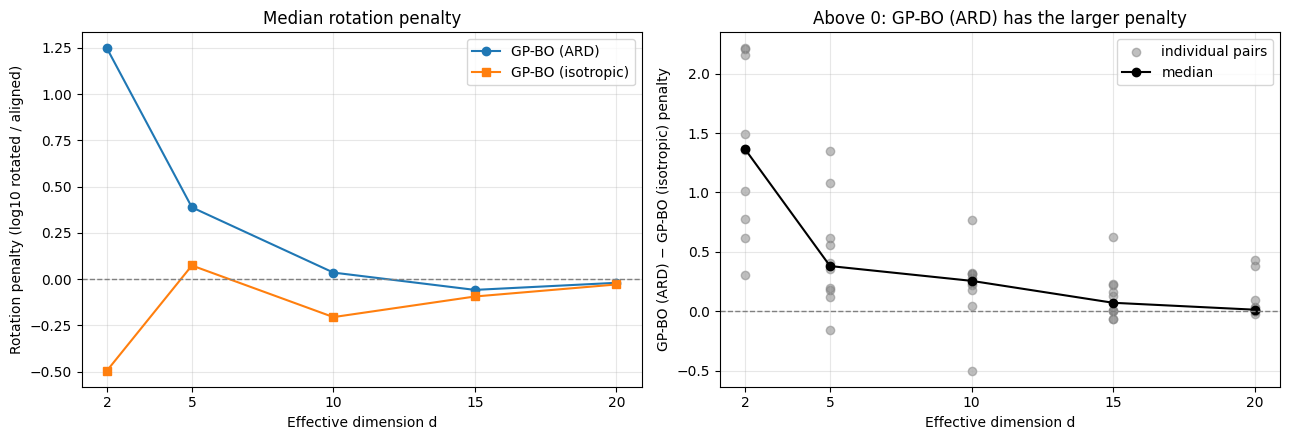

In [13]:
run_penalty = pairs.pivot_table(
    index=["d", "problem_seed", "method_seed"],
    columns="method",
    values="log10_rotation_effect",
)
h3 = run_penalty[["bo_ard", "isotropic_bo"]]

with pd.option_context("display.float_format", "{:.2f}".format):
    display(summarise_penalty_difference(h3, "bo_ard", "isotropic_bo"))

plot_penalty_comparison(h3, "bo_ard", "isotropic_bo")

### 8.1 Why: ARD length scales

Short length scale = coordinate treated as important. In the aligned case ARD should pick out the first d coordinates;
after rotation there is no coordinate structure to find.

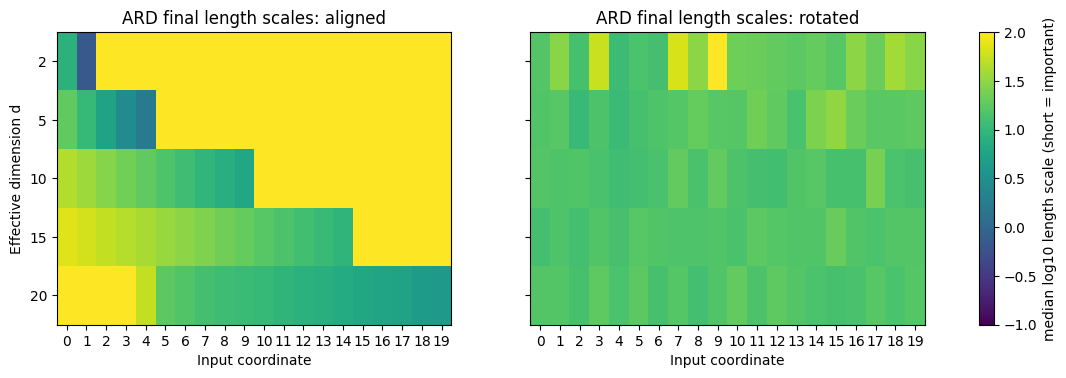

In [14]:
ard_final = final[final["method"] == "bo_ard"]
scale_columns = [f"length_scale{i}" for i in range(D)]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)

for ax, orientation in zip(axes, ["aligned", "rotated"]):
    # Median log10 length scale per coordinate over the 10 runs per d.
    scales = (
        np.log10(ard_final[ard_final["orientation"] == orientation][scale_columns])
        .groupby(ard_final["d"])
        .median()
        .reindex(EFFECTIVE_DIMS)
    )
    image = ax.imshow(scales, aspect="auto", cmap="viridis", vmin=-1, vmax=2)
    ax.set_title(f"ARD final length scales: {orientation}")
    ax.set_xticks(range(D))
    ax.set_xlabel("Input coordinate")
    ax.set_yticks(range(len(EFFECTIVE_DIMS)))
    ax.set_yticklabels(EFFECTIVE_DIMS)

axes[0].set_ylabel("Effective dimension d")
fig.colorbar(image, ax=axes, label="median log10 length scale (short = important)")
plt.show()

## 9. Additional context

### 9.1 Final value relative to CMA-ES

For each matched run, `log10(method / CMA-ES final value)`. Below 0 means the method beat CMA-ES.
Shows what the rotation penalty means in practice, e.g. whether rotation changes which method wins.

In [15]:
by_run = final.pivot_table(
    index=["d", "orientation", "problem_seed", "method_seed"],
    columns="method",
    values="best_so_far",
)

others = [m for m in available if m != "cmaes"]
relative = np.log10(by_run[others].div(by_run["cmaes"], axis=0))
relative = relative.melt(ignore_index=False, var_name="method", value_name="log10_vs_cmaes").reset_index()

relative_summary = (
    relative.groupby(["method", "d", "orientation"])["log10_vs_cmaes"]
    .agg(median="median", q25=q25, q75=q75)
    .join(
        relative.groupby(["method", "d", "orientation"])["log10_vs_cmaes"]
        .apply(lambda x: (x < 0).mean())
        .rename("fraction_beating_cmaes")
    )
    .reset_index()
)
relative_summary["method"] = relative_summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.2f}".format):
    display(relative_summary)

,method,d,orientation,median,q25,q75,fraction_beating_cmaes
0,GP-BO (ARD),2,aligned,-1.19,-1.45,-1.02,1.00
1,GP-BO (ARD),2,rotated,-0.21,-0.44,0.48,0.60
2,GP-BO (ARD),5,aligned,-0.34,-0.64,-0.20,0.90
3,GP-BO (ARD),5,rotated,0.19,-0.29,0.37,0.40
4,GP-BO (ARD),10,aligned,0.52,0.29,0.59,0.10
5,GP-BO (ARD),10,rotated,0.46,0.29,0.64,0.00
6,GP-BO (ARD),15,aligned,0.72,0.63,0.78,0.00
7,GP-BO (ARD),15,rotated,0.62,0.53,0.88,0.00
8,GP-BO (ARD),20,aligned,0.94,0.82,1.13,0.00
9,GP-BO (ARD),20,rotated,0.90,0.80,1.20,0.00


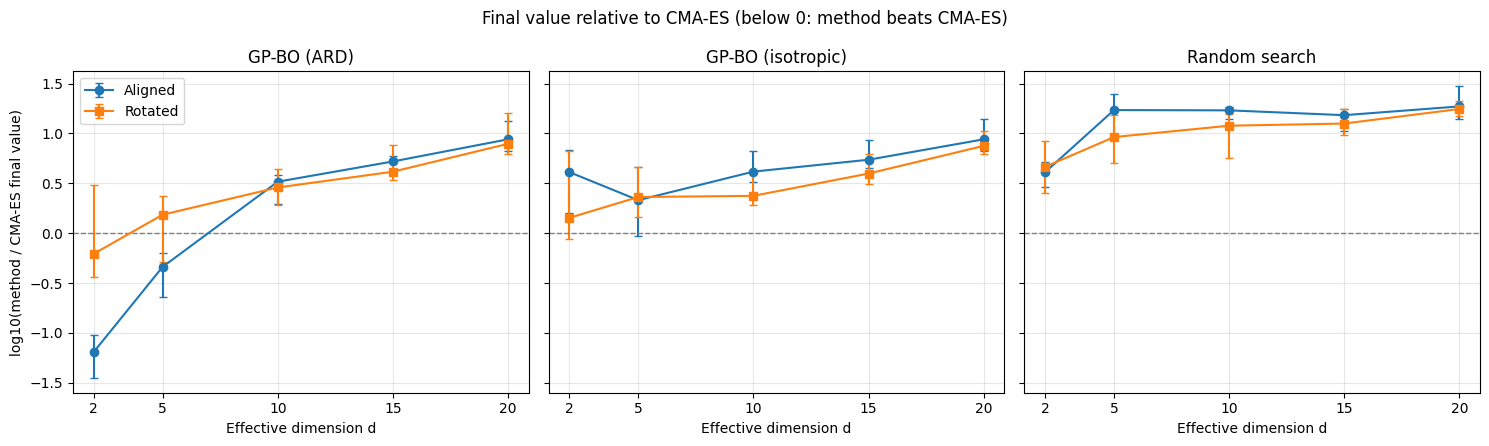

In [16]:
fig, axes = plt.subplots(1, len(others), figsize=(5 * len(others), 4.5), sharey=True)

for ax, method in zip(np.atleast_1d(axes), others):
    for orientation, marker in [("aligned", "o"), ("rotated", "s")]:
        values = relative[(relative["method"] == method) & (relative["orientation"] == orientation)]
        stats = values.groupby("d")["log10_vs_cmaes"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.errorbar(
            stats.index, stats[0.5],
            yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
            marker=marker, capsize=3, label=orientation.capitalize(),
        )

    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_xticks(EFFECTIVE_DIMS)
    ax.set_xlabel("Effective dimension d")
    ax.set_title(METHODS[method])
    ax.grid(True, alpha=0.3)

np.atleast_1d(axes)[0].set_ylabel("log10(method / CMA-ES final value)")
np.atleast_1d(axes)[0].legend()
fig.suptitle("Final value relative to CMA-ES (below 0: method beats CMA-ES)")
plt.tight_layout()
plt.show()

### 9.2 ARD vs isotropic final values

`log10(isotropic / ARD final value)` per matched run. Above 0 means ARD found the lower value.

In [17]:
if {"bo_ard", "isotropic_bo"} <= set(available):
    kernels = final[final["method"].isin(["bo_ard", "isotropic_bo"])].pivot_table(
        index=["d", "orientation", "problem_seed", "method_seed"],
        columns="method",
        values="best_so_far",
    )

    # > 0: ARD found a better (lower) final value than isotropic.
    kernels["log10_iso_over_ard"] = np.log10(kernels["isotropic_bo"] / kernels["bo_ard"])

    kernel_summary = (
        kernels.groupby(["d", "orientation"])["log10_iso_over_ard"]
        .agg(median="median", q25=q25, q75=q75)
        .unstack("orientation")
    )
    with pd.option_context("display.float_format", "{:.2f}".format):
        display(kernel_summary)
else:
    print("Needs both bo_ard and isotropic_bo results; available:", available)

median             q25             q75        
orientation aligned rotated aligned rotated aligned rotated
d                                                          
2              1.61    0.35    1.17    0.29    2.28    0.54
5              0.62    0.35    0.50   -0.09    0.95    0.65
10             0.23    0.00    0.18    0.00    0.31    0.00
15             0.01    0.00    0.00    0.00    0.15    0.00
20             0.00    0.00    0.00    0.00    0.03    0.00

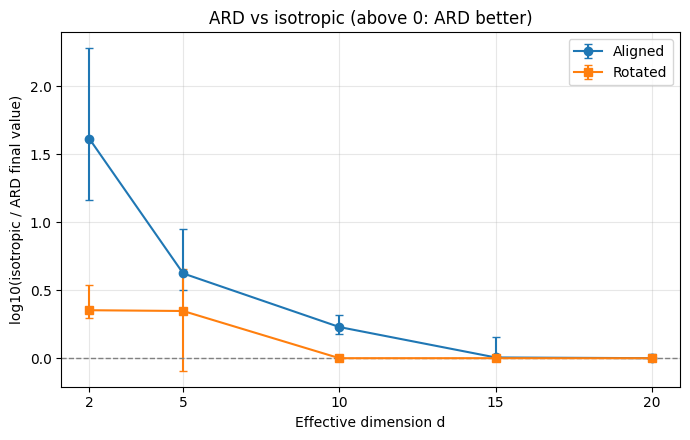

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for orientation, marker in [("aligned", "o"), ("rotated", "s")]:
    stats = kernel_summary[("median", orientation)]
    lower = stats - kernel_summary[("q25", orientation)]
    upper = kernel_summary[("q75", orientation)] - stats
    ax.errorbar(
        stats.index, stats, yerr=[lower, upper],
        marker=marker, capsize=3, label=orientation.capitalize(),
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("log10(isotropic / ARD final value)")
ax.set_title("ARD vs isotropic (above 0: ARD better)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Runtime

In [19]:
runtime = (
    final.groupby(["method", "d"])["runtime_s"]
    .median()
    .unstack("d")
    .rename(index=METHODS)
)
print("Median runtime per run (seconds)")
with pd.option_context("display.float_format", "{:.2f}".format):
    display(runtime)

Median runtime per run (seconds)


d,2,5,10,15,20
method,,,,,
GP-BO (ARD),338.81,315.48,347.90,327.98,383.46
CMA-ES,0.03,0.03,0.03,0.03,0.03
GP-BO (isotropic),25.26,25.30,32.16,27.08,26.64
Random search,0.01,0.01,0.01,0.01,0.01


## 11. Summary

_Key findings:_
- **H1:**
- **H2:**
- **H3:**